# Pandas Detailed Guide: Data Analysis & Manipulation

[Pandas](https://pandas.pydata.org/) is the standard Python library for data manipulation and analysis. It provides fast, flexible data structures designed for structured (tabular, multi-dimensional, heterogeneous) and time-series data.

---

## 0. Importing pandas
### How it works:
Pandas is imported under the standard alias `pd`. The attribute `__version__` returns the installed release string.

- **Why check `pd.__version__`?** Major updates (such as Pandas 2.0+) enforce stricter default behaviors (e.g., requiring explicit `numeric_only=True` in aggregation methods like `.mean()` and `.sum()`). Knowing your version prevents unexpected compatibility errors.

In [187]:
import pandas as pd

# version
print(pd.__version__)

3.1.0


## 1. Core Data Structures

Pandas is built upon two foundational data structures:
1. **`pd.Series`**: A 1-dimensional labeled array capable of holding any data type (integers, floats, strings, objects). Conceptually, it represents a single column of data with an associated index.
2. **`pd.DataFrame`**: A 2-dimensional labeled tabular data structure with columns of potentially different types. Think of it as a table or spreadsheet composed of multiple `Series` sharing a common index.

### 1.1 `pd.Series`
**Constructor:** `pd.Series(data=None, index=None, dtype=None, name=None)`

- **`data`**: Array-like sequence (Python list, NumPy array, dictionary, scalar).
- **`index`**: Index labels for the values. Defaults to `0, 1, 2, ... len(data)-1` if omitted.
- **`dtype`**: Data type of values. If `None`, pandas automatically infers the type (`object` for text strings).

Below, we create a 1D Series of car manufacturer names:

In [188]:
# Creating a series of car types
cars = pd.Series(["BMW", "Toyota", "Honda"])
cars

0       BMW
1    Toyota
2     Honda
dtype: str

Creating a second 1D Series of color names (using default integer indices `0, 1, 2`):

In [189]:
# Creating a series of colours
colors = pd.Series(["Red", "Blue", "White"])
colors

0      Red
1     Blue
2    White
dtype: str

### 1.2 `pd.DataFrame`
**Constructor:** `pd.DataFrame(data=None, index=None, columns=None)`

**How it works:**
A DataFrame combines multiple Series into a two-dimensional grid. When passing a Python dictionary:
- **Dictionary Keys** (`"Car"`, `"Color"`) become the **Column Headers**.
- **Dictionary Values** (the `cars` and `colors` Series) become the **Column Data**.
- Pandas automatically aligns the rows by their index labels.

In [190]:
# Creating a DataFrame of cars and colors
car_data = pd.DataFrame({"Car": cars, "Color": colors})
car_data

,Car,Color
0,BMW,Red
1,Toyota,Blue
2,Honda,White


## 2. Importing Data

Real-world workflows rarely build data manually; datasets are loaded from external sources using parser functions like `pd.read_csv()`, `pd.read_excel()`, or `pd.read_sql()`.

### `pd.read_csv()`
**Function:** `pd.read_csv(filepath_or_buffer, index_col=None, ...)`

**Parameters & Effects:**
- **`filepath_or_buffer`**: Relative or absolute path to a local file, or a URL.
- **`index_col`**: Specifies which column in the CSV should serve as the DataFrame's row index.
  - `index_col=0`: Uses the 1st column of the CSV as the index. This prevents pandas from generating an extra duplicate integer index if the file already has row numbers.
  - `index_col=None` (default): Keeps all CSV columns as regular data and generates a brand-new zero-based sequential index (`0, 1, 2, ...`).
  - `index_col="ColName"`: Uses a specific named column as the index.

In [191]:
# Import car sales data from CSV file
car_sales = pd.read_csv("data/car-sales.csv", index_col=0)
car_sales

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"
4,Nissan,White,213095,4,"$3,500.00"
5,Toyota,Green,99213,4,"$4,500.00"
6,Honda,Blue,45698,4,"$7,500.00"
7,Honda,Blue,54738,4,"$7,000.00"
8,Toyota,White,60000,4,"$6,250.00"
9,Nissan,White,31600,4,"$9,700.00"


Assigning the dataset to `df`:
> **Convention:** In data analysis and machine learning, `df` is the standard shorthand variable name for a DataFrame.

In [192]:
# Save the car sales data to df
df = pd.read_csv("data/car-sales.csv", index_col=0)
df

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"
4,Nissan,White,213095,4,"$3,500.00"
5,Toyota,Green,99213,4,"$4,500.00"
6,Honda,Blue,45698,4,"$7,500.00"
7,Honda,Blue,54738,4,"$7,000.00"
8,Toyota,White,60000,4,"$6,250.00"
9,Nissan,White,31600,4,"$9,700.00"


## 3. Exporting Data

After cleaning or transforming data, save the results back to disk using `.to_csv()`.

### `df.to_csv()`
**Method:** `df.to_csv(path_or_buf, index=True, header=True, sep=',')`

**Parameters & Effects:**
- **`path_or_buf`**: Destination path for the exported file.
- **`index`**: Controls whether to write the DataFrame's row index to the CSV.
  - `index=True` (default): Writes the row index as the first column in the file. If this CSV is later read without `index_col=0`, it creates an unwanted column (often called `Unnamed: 0`).
  - `index=False`: Skips writing row index labels, saving only the actual data columns.
- **`header`**: Whether to write column names as the first line (`True` by default).

In [193]:
# Export the car sales data to a new CSV file
df.to_csv("data/exported-car-sales.csv")

### 3.1 Importing Directly from Remote URLs
`pd.read_csv()` is network-aware: passing an HTTP/HTTPS URL downloads the raw text into memory and parses it directly into a DataFrame without requiring manual download or disk storage.

In [194]:
# Importing Heart Disease dataset
patient_data = pd.read_csv("https://github.com/mrdbourke/zero-to-mastery-ml/raw/81492352d12d7a52caef57bba7744cbdc34af33f/data/heart-disease.csv")
patient_data.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


### 3.2 Exporting with `index=False`
Here, `index=False` ensures only the patient medical columns are written to disk, preventing an unwanted row index column when re-imported:

In [195]:
# Export the patient data to a new CSV file
patient_data.to_csv("data/exported-patient-data.csv", index=False)

## 4. Describing Data

Exploring dataset structure, data types, and summary statistics.

### Attributes vs. Methods:
- **Attributes** (no parentheses, e.g., `.dtypes`, `.columns`, `.index`): Access pre-existing metadata and structural properties. They execute immediately without computing new values.
- **Methods** (with parentheses, e.g., `.describe()`, `.info()`, `.mean()`): Functions that perform calculations, transformations, or summaries when called.

In [196]:
car_sales

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"
4,Nissan,White,213095,4,"$3,500.00"
5,Toyota,Green,99213,4,"$4,500.00"
6,Honda,Blue,45698,4,"$7,500.00"
7,Honda,Blue,54738,4,"$7,000.00"
8,Toyota,White,60000,4,"$6,250.00"
9,Nissan,White,31600,4,"$9,700.00"


### 4.1 Checking Data Types: `.dtypes`
**Attribute:** `df.dtypes`

Returns a `Series` containing the data type (`dtype`) of each column:
- **`object`**: Text/strings, or mixed types.
- **`int64`**: 64-bit integer numbers.
- **`float64`**: 64-bit floating point decimal numbers.

In [197]:
car_sales.dtypes

Make               str
Colour             str
Odometer (KM)    int64
Doors            int64
Price              str
dtype: object

> **Key Observation:** Notice that `Price` is listed as `object` (string) rather than integer/float. This is because the values contain currency symbols (`$`) and formatting commas (`,`), which pandas treats as text.

### 4.2 Summary Statistics: `.describe()`
**Method:** `df.describe(percentiles=None, include=None, exclude=None)`

**How it works:**
Calculates central tendency, dispersion, and shape of a dataset's distribution.
- By default, it computes metrics **only for numeric columns** (`int64`, `float64`):
  - `count`: Number of non-null values.
  - `mean`: Average value.
  - `std`: Standard deviation (measure of data spread).
  - `min` / `max`: Minimum and maximum values.
  - `25%`, `50%`, `75%`: Percentile quartiles (`50%` is the median).
- **Parameter `include='all'`**: Can be used to include non-numeric columns (adds `unique`, `top`, and `freq`).

In [198]:
car_sales.describe()

,Odometer (KM),Doors
count,10.000000,10.000000
mean,78601.400000,4.000000
std,61983.471735,0.471405
min,11179.000000,3.000000
25%,35836.250000,4.000000
50%,57369.000000,4.000000
75%,96384.500000,4.000000
max,213095.000000,5.000000


### 4.3 Structural Information: `.info()`
**Method:** `df.info(verbose=None, memory_usage=None, show_counts=None)`

**How it works:**
Prints a comprehensive diagnostic summary:
1. Total row count and index range (`RangeIndex: 10 entries, 0 to 9`).
2. Total column count.
3. Column names and **non-null counts** (instantly reveals missing data if `Non-Null Count` < total entries).
4. Data type of each column.
5. Total memory footprint occupied by the DataFrame.

In [199]:
car_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Make           10 non-null     str  
 1   Colour         10 non-null     str  
 2   Odometer (KM)  10 non-null     int64
 3   Doors          10 non-null     int64
 4   Price          10 non-null     str  
dtypes: int64(2), str(3)
memory usage: 532.0 bytes


### 4.4 Aggregation: `.mean()`
**Method:** `df.mean(axis=0, numeric_only=False)`

**Parameters & Effects:**
- **`numeric_only`**:
  - `numeric_only=True`: Averages only numeric columns (`int`, `float`), safely skipping text columns.
  - `numeric_only=False` (default in older versions): Attempts to calculate the mean of all columns. In modern pandas (v2.0+), this raises a `TypeError` because text strings cannot be averaged!
- **`axis`**:
  - `axis=0` (or `'index'`, default): Computes the mean down columns (one mean per column).
  - `axis=1` (or `'columns'`): Computes the mean across rows.

In [200]:
# Mean
car_sales.mean(numeric_only=True)

Odometer (KM)    78601.4
Doors                4.0
dtype: float64

Calling `.mean()` directly on an independent `pd.Series`:

In [201]:
# Calling mean on a series
car_price = pd.Series([1000, 1500, 2000])
car_price.mean()

np.float64(1500.0)

Calling `.mean()` on an individual DataFrame column (which returns a scalar float):

In [202]:
# Calling mean on a specific column
car_sales["Odometer (KM)"].mean()

np.float64(78601.4)

### 4.5 Aggregation: `.sum()`
**Method:** `df.sum(axis=0, numeric_only=False)`

**Parameters & Effects:**
- **`numeric_only=False`**: Sums all columns. For numeric columns, it computes arithmetic sum. For string columns, it **concatenates** strings together into one continuous text block:

In [203]:
# Calling sum on a DataFrame with numeric_only=False (default)
car_sales.sum(numeric_only=False)

Make             ToyotaHondaToyotaBMWNissanToyotaHondaHondaToyo...
Colour               WhiteRedBlueBlackWhiteGreenBlueBlueWhiteWhite
Odometer (KM)                                               786014
Doors                                                           40
Price            $4,000.00$5,000.00$7,000.00$22,000.00$3,500.00...
dtype: object

- **`numeric_only=True`**: Excludes string columns and sums numeric values only:

In [204]:
# Calling sum on a DataFrame with numeric_only=True
car_sales.sum(numeric_only=True)

Odometer (KM)    786014
Doors                40
dtype: int64

Summing values of a single column:

In [205]:
# Calling sum on a Series
car_sales["Odometer (KM)"].sum()

np.int64(786014)

### 4.6 Inspecting Columns & Indices
- **`df.columns`**: Attribute returning an `Index` array of all column labels. Columns can be sliced or indexed like Python lists:

In [206]:
# Show all column of the DataFrame
car_sales.columns

Index(['Make', 'Colour', 'Odometer (KM)', 'Doors', 'Price'], dtype='str')

Extracting the first column name via zero-based indexing:

In [207]:
# Save car_sales columns to a list
car_columns = car_sales.columns
car_columns[0]

'Make'

- **`df.index`**: Attribute returning row labels. For default indices, returns a `RangeIndex` object with `start`, `stop`, and `step` values:

In [208]:
# Show all index of the DataFrame
car_sales.index

RangeIndex(start=0, stop=10, step=1)

### 4.7 Row Count: `len(df)`
Standard Python built-in `len()` returns the total number of rows (length of the row index):

In [209]:
# Show the length of the DataFrame
len(car_sales)

10

## 5. Viewing and Selecting Data

Inspecting subsets of rows, columns, or specific cells.

### Quick Methods:
- **`df.head(n=5)`**: Returns the first `n` rows.
- **`df.tail(n=5)`**: Returns the last `n` rows.
- **`df.loc[]`**: Selects by **label** (matches index names).
- **`df.iloc[]`**: Selects by **integer position** (0-based indexing).

In [210]:
# Show the first 5 rows of the DataFrame
car_sales.head()

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"
4,Nissan,White,213095,4,"$3,500.00"


Pass an integer `n` to `.head(n)` to view a custom number of rows from the top:

In [211]:
# Show first 3 rows of the DataFrame
car_sales.head(3)

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"


View the bottom 5 rows with `.tail()` (useful for checking end-of-file rows or footer errors):

In [212]:
# Show bottom 5 rows of the DataFrame
car_sales.tail()

,Make,Colour,Odometer (KM),Doors,Price
5,Toyota,Green,99213,4,"$4,500.00"
6,Honda,Blue,45698,4,"$7,500.00"
7,Honda,Blue,54738,4,"$7,000.00"
8,Toyota,White,60000,4,"$6,250.00"
9,Nissan,White,31600,4,"$9,700.00"


### 5.1 Deep Dive: `.loc` vs. `.iloc`

The core distinction to remember:
- **`.loc` (Label-based)**: Refers to the **explicit index labels** of rows and columns.
- **`.iloc` (Integer position-based)**: Refers to the **0-indexed sequential position** (`0, 1, 2, ...`), identical to standard Python lists.

To see the difference, let's create a Series with custom, out-of-order, and duplicate index labels:

In [213]:
# Create a sample series
animals = pd.Series(["cat", "dog", "bird", "panda", "snake"], index=[0, 3, 9, 8, 3])
animals

0      cat
3      dog
9     bird
8    panda
3    snake
dtype: str

**Using `.loc[3]`:**
Retrieves all items whose index label equals `3`. Because label `3` appears twice, it returns both rows (`"dog"` and `"snake"`):

In [214]:
# Select all indexed with 3
animals.loc[3]

3      dog
3    snake
dtype: str

Retrieving item with label `9` via `.loc[9]` (returns `"bird"`):

In [215]:
# Select index 9
animals.loc[9]

'bird'

Viewing `car_sales` before testing `.loc` on a DataFrame:

In [216]:
car_sales

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"
4,Nissan,White,213095,4,"$3,500.00"
5,Toyota,Green,99213,4,"$4,500.00"
6,Honda,Blue,45698,4,"$7,500.00"
7,Honda,Blue,54738,4,"$7,000.00"
8,Toyota,White,60000,4,"$6,250.00"
9,Nissan,White,31600,4,"$9,700.00"


In `car_sales`, index labels happen to match integers `0` to `9`. Calling `.loc[3]` retrieves the row with label `3`:

In [217]:
# Select row at index 3
car_sales.loc[3]

Make                    BMW
Colour                Black
Odometer (KM)         11179
Doors                     5
Price            $22,000.00
Name: 3, dtype: object

Now let's examine `.iloc` on the `animals` Series:

In [218]:
animals

0      cat
3      dog
9     bird
8    panda
3    snake
dtype: str

**Using `.iloc[3]`:**
Retrieves the element at **integer position 3** (the 4th item, 0-indexed).
Even though its index label is `8`, `.iloc[3]` selects `"panda"`:

In [219]:
# Select a row at position 3 [not index 3]
animals.iloc[3]     # index = 8

'panda'

### 5.2 Slicing with `.iloc` vs. `.loc`

**Crucial Slicing Rule:**
- **`.iloc[:3]` (Position)**: Standard Python slicing. The stop position is **EXCLUSIVE** (returns positions 0, 1, 2 — 3 items total).
- **`.loc[:3]` (Label)**: Label slicing. The stop label is **INCLUSIVE** (returns everything up to and including the label `3`):

In [220]:
# Get all rows upto position 3
animals.iloc[:3]

0     cat
3     dog
9    bird
dtype: str

Slicing `car_sales` with `.loc[:3]` includes row label `3` (giving 4 rows: 0, 1, 2, 3):

In [221]:
# Get all rows upto index 3
car_sales.loc[:3]

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"


### 5.3 Column Selection
- **`df["ColumnName"]`**: Standard and safest syntax. Works with any column name, including those with spaces or punctuation.
- **`df.ColumnName`**: Attribute syntax (e.g., `df.Colour`). Only works if the column name has no spaces and does not conflict with DataFrame method names.

In [222]:
# Get all rows for the "Colour" column
car_sales["Colour"]

0    White
1      Red
2     Blue
3    Black
4    White
5    Green
6     Blue
7     Blue
8    White
9    White
Name: Colour, dtype: str

Selecting a column using `.loc[:, "ColumnName"]`:
- The colon `:` before the comma means **"select all rows"**.
- `"Colour"` after the comma specifies the **column to extract**:

In [223]:
# Another way to get all rows for the "Colour" column
car_sales.loc[:, "Colour"]      # ":" stands for all rows, "Colour" is the column name

0    White
1      Red
2     Blue
3    Black
4    White
5    Green
6     Blue
7     Blue
8    White
9    White
Name: Colour, dtype: str

### 5.4 Boolean Indexing (Filtering Data)

**How it works:**
1. A condition like `car_sales["Odometer (KM)"] > 100000` evaluates each row and generates a boolean Series (`True` or `False`).
2. Passing that boolean Series into `df[...]` filters the rows, retaining only those where the condition is `True`.

In [224]:
# Select cars with over 100,000 KM on the odometer
car_sales[car_sales["Odometer (KM)"] > 100000]

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
4,Nissan,White,213095,4,"$3,500.00"


Filtering rows matching an exact equality condition (`Make == "Toyota"`):

In [225]:
# Select cars that made by "Toyota"
car_sales[car_sales["Make"] == "Toyota"]

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
5,Toyota,Green,99213,4,"$4,500.00"
8,Toyota,White,60000,4,"$6,250.00"


### 5.5 Comparing & Grouping Columns

#### `pd.crosstab()`
**Function:** `pd.crosstab(index, columns)`
- **`index`**: Values to group by in rows.
- **`columns`**: Values to group by in columns.
- **Effect:** Creates a frequency contingency table showing how many times each combination occurs (e.g. how many 4-door Toyotas vs 3-door Toyotas):

In [226]:
# Compare car Make with number of Doors
pd.crosstab(car_sales["Make"], car_sales["Doors"])

Doors,3,4,5
Make,,,
BMW,0,0,1
Honda,0,3,0
Nissan,0,2,0
Toyota,1,3,0


Reviewing `car_sales` before grouping:

In [227]:
car_sales

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"
4,Nissan,White,213095,4,"$3,500.00"
5,Toyota,Green,99213,4,"$4,500.00"
6,Honda,Blue,45698,4,"$7,500.00"
7,Honda,Blue,54738,4,"$7,000.00"
8,Toyota,White,60000,4,"$6,250.00"
9,Nissan,White,31600,4,"$9,700.00"


#### 5.5.2 Deep Dive into Grouping: `df.groupby()`
**Method:** `df.groupby(by, as_index=True, sort=True, numeric_only=False, dropna=True)`

**How it works (The Split-Apply-Combine Pattern):**
1. **Split**: The dataset is divided into distinct subsets (buckets) based on unique values in the specified grouping key(s).
2. **Apply**: An aggregation function (`.mean()`, `.sum()`, `.count()`, `.agg()`, `.std()`, `.min()`, `.max()`) is computed independently for each group.
3. **Combine**: The individual group calculations are glued back together into a single cohesive summary DataFrame.

**Parameters & Effects:**
- **`by`**: Column label string (e.g. `'Make'`), list of column labels (e.g. `['Make', 'Doors']`), or Series.
  - Single column: Groups along one dimension.
  - List of columns: Multi-level / hierarchical grouping (creates a MultiIndex).
- **`as_index`**:
  - `as_index=True` *(default)*: Grouping column(s) become the **index** of the output DataFrame.
  - `as_index=False`: Keeps grouping column(s) as standard data columns (creates a flat, SQL-like table output).
- **`numeric_only`**:
  - `numeric_only=True`: Aggregates only numeric columns (`int`, `float`), safely skipping string/text columns.
  - `numeric_only=False`: Attempts to aggregate all columns. (Note: in pandas 2.0+, functions like `.mean()` raise a `TypeError` if non-numeric columns cannot be averaged).
- **`sort`**:
  - `sort=True` *(default)*: Sorts group keys in ascending/alphabetical order.
  - `sort=False`: Preserves the order in which groups first appear in the original data (faster on large datasets).
- **`dropna`**:
  - `dropna=True` *(default)*: Drops rows where the grouping key is `NaN`.
  - `dropna=False`: Treats `NaN` as its own distinct group.

---

**Example 1: Basic GroupBy with Single Aggregation**
Group by `Make` and calculate the average across all numeric columns (`numeric_only=True`):

In [228]:
# Group by the Make column and then get the average of other columns
car_sales.groupby(["Make"]).mean(numeric_only=True)

,Odometer (KM),Doors
Make,,
BMW,11179.000000,5.00
Honda,62778.333333,4.00
Nissan,122347.500000,4.00
Toyota,85451.250000,3.75


**Example 2: Selecting a Specific Column After Grouping**
Instead of calculating the mean across every numerical column, isolate and aggregate a single column (e.g. `"Odometer (KM)"`):

In [229]:
# Group by Make and calculate the average of only the Odometer column
car_sales.groupby("Make")["Odometer (KM)"].mean()

Make
BMW        11179.000000
Honda      62778.333333
Nissan    122347.500000
Toyota     85451.250000
Name: Odometer (KM), dtype: float64

**Example 3: Multiple Aggregations Using `.agg()`**
Compute multiple statistical summaries (`mean`, `median`, `count`, `min`, `max`) simultaneously on a grouped column:

In [230]:
# Compute multiple summary statistics at once using .agg()
car_sales.groupby("Make")["Odometer (KM)"].agg(["mean", "median", "count", "min", "max"])

,mean,median,count,min,max
Make,,,,,
BMW,11179.000000,11179.0,1,11179,11179
Honda,62778.333333,54738.0,3,45698,87899
Nissan,122347.500000,122347.5,2,31600,213095
Toyota,85451.250000,79606.5,4,32549,150043


**Example 4: Column-Specific Aggregations with a Dictionary**
Apply different aggregation functions to different columns in a single operation:

In [231]:
# Apply different aggregations to different columns using a dictionary
car_sales.groupby("Make").agg({
    "Odometer (KM)": ["mean", "max"],
    "Doors": "median"
})

Odometer (KM)          Doors
                 mean     max median
Make                                
BMW      11179.000000   11179    5.0
Honda    62778.333333   87899    4.0
Nissan  122347.500000  213095    4.0
Toyota   85451.250000  150043    4.0

**Example 5: Grouping by Multiple Columns (Hierarchical / MultiIndex)**
Pass a list of column names `["Make", "Doors"]` to group rows by multiple dimensions simultaneously:

In [232]:
# Group by both "Make" and "Doors"
car_sales.groupby(["Make", "Doors"]).mean(numeric_only=True)

Odometer (KM)
Make   Doors               
BMW    5       11179.000000
Honda  4       62778.333333
Nissan 4      122347.500000
Toyota 3       32549.000000
       4      103085.333333

**Example 6: Flat Output with `as_index=False` (SQL-style Output)**
By default, the grouped column becomes the index. Setting `as_index=False` keeps the grouping key as a regular column:

In [233]:
# Keep "Make" as a standard data column instead of row index
car_sales.groupby("Make", as_index=False)["Odometer (KM)"].mean()

,Make,Odometer (KM)
0,BMW,11179.000000
1,Honda,62778.333333
2,Nissan,122347.500000
3,Toyota,85451.250000


**Example 7: Group Frequency Counts with `.size()`**
Count the total number of records belonging to each category:

In [234]:
# Count the number of rows in each group
car_sales.groupby("Make").size()

Make
BMW       1
Honda     3
Nissan    2
Toyota    4
dtype: int64

### 5.6 Data Visualization with Matplotlib & Pandas

Pandas provides direct plotting wrappers built on top of Matplotlib.
- **`%matplotlib inline`**: Jupyter magic command directing Matplotlib to render charts inline directly below code cells instead of opening separate pop-up windows.
- **Semicolon `;` at end of plot lines**: Suppresses the returned text representation of the Matplotlib Axes object (`<Axes: ...>`).

In [235]:
# Import matlot;in and tell jupyter to show plots inline (in the notebook)
import matplotlib.pyplot as plt
%matplotlib inline

Line plot of a single numerical column (plots values sequentially against the row index):

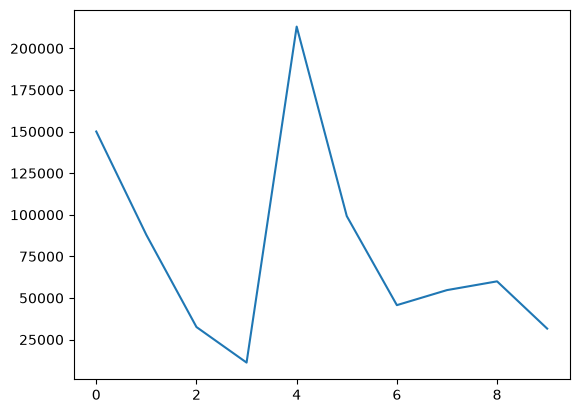

In [236]:
car_sales["Odometer (KM)"].plot(); # use ";" to suppress the output of the plot function in Jupyter Notebook

Relational plot specifying explicit `x` and `y` axes:
- **`x="Make"`**: Categorical values along the horizontal axis.
- **`y="Odometer (KM)"`**: Numerical values along the vertical axis.

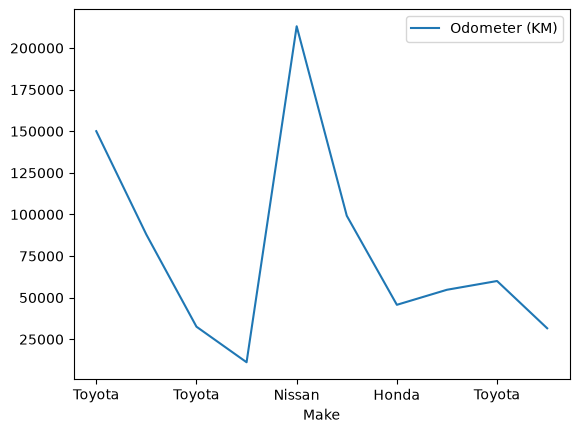

In [237]:
car_sales.plot(x = "Make", y = "Odometer (KM)");

### 5.7 Histograms: `.hist()`
**Method:** `df["Col"].hist(bins=10)`

**How it works:**
Groups continuous numeric data into ranges (bins) and displays the count of data points in each bin, showing data distribution and skewness:

<Axes: >

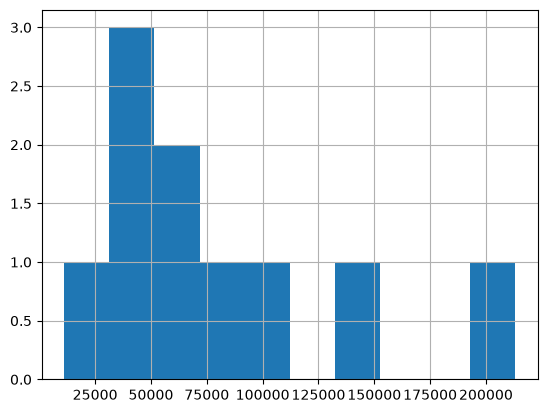

In [238]:
car_sales["Odometer (KM)"].hist()

Attempting to plot the `Price` column directly:

In [239]:
car_sales["Price"].plot()

TypeError: no numeric data to plot

> **Why did plotting `Price` fail?**
> As discovered earlier with `.dtypes` and confirmed below with `.info()`, `Price` is stored as `object` (string text) because of `$` and commas. Matplotlib cannot plot strings as numerical coordinates.

In [240]:
car_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Unnamed: 0     10 non-null     int64
 1   Make           10 non-null     str  
 2   Colour         10 non-null     str  
 3   Odometer (KM)  10 non-null     int64
 4   Doors          10 non-null     int64
 5   Price          10 non-null     str  
dtypes: int64(3), str(3)
memory usage: 612.0 bytes


### 5.8 Cleaning & Converting String Columns to Numbers

To clean `Price` (e.g. `"$4,000.00"` -> `4000`), we chain three operations:
1. **`.str.replace(r'[$,]', '', regex=True)`**:
   - `pat=r'[$,]'`: Regular expression matching either `$` or `,`.
   - `repl=''`: Replaces matched symbols with an empty string (removes them).
   - `regex=True`: Tells pandas to treat the pattern as a regular expression.
2. **`.astype(float)`**: Converts decimal string `"4000.00"` to float `4000.0`. (Direct conversion to `int` would raise a `ValueError` on decimal points).
3. **`.astype(int)`**: Casts float `4000.0` to integer `4000`.

In [241]:
# Change the Price column to integers (from strings)
# Remove dollar signs and commas, then convert strings to integers
# Remove dollar signs and commas, then convert strings to integers
car_sales["Price"] = (
    car_sales["Price"]
    .str.replace(r'[$,]', '', regex=True)
    .astype(float)
    .astype(int)
)

car_sales

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,4000
1,Honda,Red,87899,4,5000
2,Toyota,Blue,32549,3,7000
3,BMW,Black,11179,5,22000
4,Nissan,White,213095,4,3500
5,Toyota,Green,99213,4,4500
6,Honda,Blue,45698,4,7500
7,Honda,Blue,54738,4,7000
8,Toyota,White,60000,4,6250
9,Nissan,White,31600,4,9700


Verify that the data type of `Price` is now `int64`:

In [242]:
car_sales.dtypes

Make               str
Colour             str
Odometer (KM)    int64
Doors            int64
Price            int64
dtype: object

Now that `Price` is numeric, plotting executes without error:

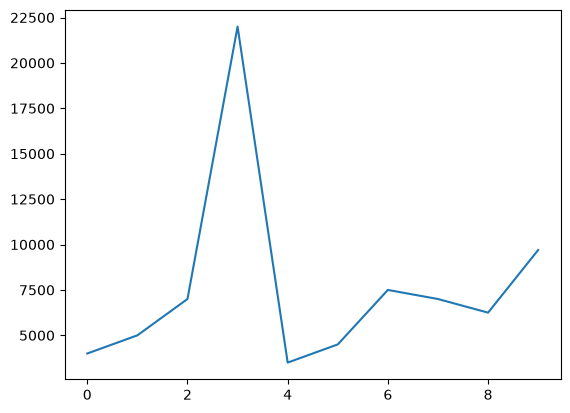

In [243]:
car_sales["Price"].plot();

## 6. Manipulating Data

Techniques for transforming data, imputing missing values, adding/dropping columns, and applying custom functions.

### 6.1 String Operations: `.str`
Pandas provides the `.str` accessor to perform vectorized string operations.
- **Important:** Methods like `.str.lower()` do **not** modify the original DataFrame; they return a transformed copy:

In [244]:
# Lower the Make column
car_sales["Make"].str.lower()

0    toyota
1     honda
2    toyota
3       bmw
4    nissan
5    toyota
6     honda
7     honda
8    toyota
9    nissan
Name: Make, dtype: str

Inspecting `car_sales.head()` confirms that without assignment, `Make` remains capitalized:

In [245]:
# View top 5 rows
car_sales.head()

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,4000
1,Honda,Red,87899,4,5000
2,Toyota,Blue,32549,3,7000
3,BMW,Black,11179,5,22000
4,Nissan,White,213095,4,3500


Reassigning the transformed Series back to `car_sales["Make"]` makes the change permanent:

In [246]:
# Set the Make column to lowercase
car_sales["Make"] = car_sales["Make"].str.lower()
car_sales.head()

,Make,Colour,Odometer (KM),Doors,Price
0,toyota,White,150043,4,4000
1,honda,Red,87899,4,5000
2,toyota,Blue,32549,3,7000
3,bmw,Black,11179,5,22000
4,nissan,White,213095,4,3500


### 6.2 Handling Missing Data (`NaN`)

Missing data in pandas is represented as `NaN` (Not a Number). Let's load a sample dataset with missing values from GitHub:

In [247]:
# Load car sales data with missing values from GitHub (if the file is hosted online)
car_sales_missing = pd.read_csv("https://raw.githubusercontent.com/mrdbourke/zero-to-mastery-ml/master/data/car-sales-missing-data.csv")
car_sales_missing

,Make,Colour,Odometer,Doors,Price
0,Toyota,White,150043.0,4.0,"$4,000"
1,Honda,Red,87899.0,4.0,"$5,000"
2,Toyota,Blue,NaN,3.0,"$7,000"
3,BMW,Black,11179.0,5.0,"$22,000"
4,Nissan,White,213095.0,4.0,"$3,500"
5,Toyota,Green,NaN,4.0,"$4,500"
6,Honda,NaN,NaN,4.0,"$7,500"
7,Honda,Blue,NaN,4.0,NaN
8,Toyota,White,60000.0,NaN,NaN
9,NaN,White,31600.0,4.0,"$9,700"


### 6.3 Imputing Missing Values: `.fillna()`
**Method:** `df["Col"].fillna(value, inplace=False)`

**Parameters & Effects:**
- **`value`**: The replacement value (e.g. scalar number, string, or computed aggregate like `.mean()`).
- **`inplace`**:
  - `inplace=False` (default): Returns a new modified Series. The original DataFrame remains untouched.
  - `inplace=True`: Mutates the calling DataFrame directly in memory and returns `None`.

In [248]:
# Fill Odometer missing values with the mean of the column
car_sales_missing["Odometer"].fillna(
    car_sales_missing["Odometer"].mean(),
    inplace=False
)       # inplace=False means that the original DataFrame will not be modified, and a new DataFrame with the filled values will be returned.

0    150043.000000
1     87899.000000
2     92302.666667
3     11179.000000
4    213095.000000
5     92302.666667
6     92302.666667
7     92302.666667
8     60000.000000
9     31600.000000
Name: Odometer, dtype: float64

Checking `car_sales_missing` confirms `NaN` entries still exist because `inplace=False` was used:

In [249]:
car_sales_missing

,Make,Colour,Odometer,Doors,Price
0,Toyota,White,150043.0,4.0,"$4,000"
1,Honda,Red,87899.0,4.0,"$5,000"
2,Toyota,Blue,NaN,3.0,"$7,000"
3,BMW,Black,11179.0,5.0,"$22,000"
4,Nissan,White,213095.0,4.0,"$3,500"
5,Toyota,Green,NaN,4.0,"$4,500"
6,Honda,NaN,NaN,4.0,"$7,500"
7,Honda,Blue,NaN,4.0,NaN
8,Toyota,White,60000.0,NaN,NaN
9,NaN,White,31600.0,4.0,"$9,700"


> ### Quick Guide Tip: Best Practice for In-Place Updates
> To permanently update a column, choose **one** of these two approaches:
> 1. **Reassignment (Recommended):** `df["col"] = df["col"].fillna(...)`
> 2. **In-place Mutation:** `df["col"].fillna(..., inplace=True)`
> 
> **Warning:** Never combine both: `df["col"] = df["col"].fillna(..., inplace=True)`! Because `inplace=True` returns `None`, assigning it back would overwrite your column with `None`!

In [250]:
# Fill Odometer missing values with the mean of the column
car_sales_missing["Odometer"] = car_sales_missing["Odometer"].fillna(
                                car_sales_missing["Odometer"].mean(),
                                inplace=True
                            )


/tmp/ipykernel_6624/1956478489.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  car_sales_missing["Odometer"] = car_sales_missing["Odometer"].fillna(


Verifying that `Odometer` missing entries are now filled with the column mean:

In [251]:
car_sales_missing

,Make,Colour,Odometer,Doors,Price
0,Toyota,White,150043.000000,4.0,"$4,000"
1,Honda,Red,87899.000000,4.0,"$5,000"
2,Toyota,Blue,92302.666667,3.0,"$7,000"
3,BMW,Black,11179.000000,5.0,"$22,000"
4,Nissan,White,213095.000000,4.0,"$3,500"
5,Toyota,Green,92302.666667,4.0,"$4,500"
6,Honda,NaN,92302.666667,4.0,"$7,500"
7,Honda,Blue,92302.666667,4.0,NaN
8,Toyota,White,60000.000000,NaN,NaN
9,NaN,White,31600.000000,4.0,"$9,700"


### 6.4 Dropping Missing Values: `.dropna()`
**Method:** `df.dropna(axis=0, how='any', subset=None, inplace=False)`

**Parameters & Effects:**
- **`axis`**:
  - `axis=0` (or `'index'`, default): Drops **rows** containing missing values.
  - `axis=1` (or `'columns'`): Drops **columns** containing missing values.
- **`how`**:
  - `how='any'` (default): Drops the row/column if **any** value is `NaN`.
  - `how='all'`: Drops the row/column only if **all** values are `NaN`.
- **`subset`**: List of column names to check for missing values, ignoring NaNs in other columns.
- **`inplace`**: If `False` (default), returns a copy; if `True`, drops rows in-place.

In [252]:
# Remove Missing data
car_sales_missing.dropna()

,Make,Colour,Odometer,Doors,Price
0,Toyota,White,150043.000000,4.0,"$4,000"
1,Honda,Red,87899.000000,4.0,"$5,000"
2,Toyota,Blue,92302.666667,3.0,"$7,000"
3,BMW,Black,11179.000000,5.0,"$22,000"
4,Nissan,White,213095.000000,4.0,"$3,500"
5,Toyota,Green,92302.666667,4.0,"$4,500"


Because `inplace=False` was used above, rows with missing values are still present:

In [253]:
car_sales_missing

,Make,Colour,Odometer,Doors,Price
0,Toyota,White,150043.000000,4.0,"$4,000"
1,Honda,Red,87899.000000,4.0,"$5,000"
2,Toyota,Blue,92302.666667,3.0,"$7,000"
3,BMW,Black,11179.000000,5.0,"$22,000"
4,Nissan,White,213095.000000,4.0,"$3,500"
5,Toyota,Green,92302.666667,4.0,"$4,500"
6,Honda,NaN,92302.666667,4.0,"$7,500"
7,Honda,Blue,92302.666667,4.0,NaN
8,Toyota,White,60000.000000,NaN,NaN
9,NaN,White,31600.000000,4.0,"$9,700"


Permanently dropping all rows containing `NaN` using `inplace=True`:

In [254]:
# Remove all rows with missing values
car_sales_missing.dropna(inplace=True)
car_sales_missing = car_sales_missing.dropna()

/tmp/ipykernel_6624/224572199.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  car_sales_missing.dropna(inplace=True)


The dataset now contains only complete rows:

In [255]:
car_sales_missing

,Make,Colour,Odometer,Doors,Price
0,Toyota,White,150043.000000,4.0,"$4,000"
1,Honda,Red,87899.000000,4.0,"$5,000"
2,Toyota,Blue,92302.666667,3.0,"$7,000"
3,BMW,Black,11179.000000,5.0,"$22,000"
4,Nissan,White,213095.000000,4.0,"$3,500"
5,Toyota,Green,92302.666667,4.0,"$4,500"


### 6.5 Creating & Adding New Columns

There are 4 common ways to create a new column:
1. **From a `pd.Series`**: Aligns values by row index. If the Series has fewer elements, missing indices receive `NaN`.
2. **From a Python `list`**: Must match the DataFrame's length **exactly** (otherwise raises `ValueError`).
3. **From existing columns**: Arithmetic computations (e.g. `Price / Odometer`).
4. **From a scalar value**: Automatically broadcast (replicated) across all rows.

**Method 1: Adding a column from a Series:**

In [256]:
# Create a collumn in the DataFrame
seats_column = pd.Series([5, 5, 5, 5, 5, 5, 5, 5, 5, 5])
car_sales["Seats"] = seats_column
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Seats
0,toyota,White,150043,4,4000,5
1,honda,Red,87899,4,5000,5
2,toyota,Blue,32549,3,7000,5
3,bmw,Black,11179,5,22000,5
4,nissan,White,213095,4,3500,5
5,toyota,Green,99213,4,4500,5
6,honda,Blue,45698,4,7500,5
7,honda,Blue,54738,4,7000,5
8,toyota,White,60000,4,6250,5
9,nissan,White,31600,4,9700,5


**Method 2: Adding a column from a Python list:**
> **Note:** The list must contain exactly 10 values to match the 10 rows in `car_sales`.

In [257]:
# Create a column from pthon list
engine_sizes = [1.0, 1.3, 1.5, 1.8, 2.0, 2.2, 2.5, 3.0, 3.5, 4.0]
car_sales["Engine Size"] = engine_sizes
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size
0,toyota,White,150043,4,4000,5,1.0
1,honda,Red,87899,4,5000,5,1.3
2,toyota,Blue,32549,3,7000,5,1.5
3,bmw,Black,11179,5,22000,5,1.8
4,nissan,White,213095,4,3500,5,2.0
5,toyota,Green,99213,4,4500,5,2.2
6,honda,Blue,45698,4,7500,5,2.5
7,honda,Blue,54738,4,7000,5,3.0
8,toyota,White,60000,4,6250,5,3.5
9,nissan,White,31600,4,9700,5,4.0


**Method 3: Creating a column from arithmetic calculation between existing columns:**

In [258]:
# Column from other column
car_sales["Price per KM"] = car_sales["Price"] / car_sales["Odometer (KM)"]
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM
0,toyota,White,150043,4,4000,5,1.0,0.026659
1,honda,Red,87899,4,5000,5,1.3,0.056883
2,toyota,Blue,32549,3,7000,5,1.5,0.215060
3,bmw,Black,11179,5,22000,5,1.8,1.967976
4,nissan,White,213095,4,3500,5,2.0,0.016425
5,toyota,Green,99213,4,4500,5,2.2,0.045357
6,honda,Blue,45698,4,7500,5,2.5,0.164121
7,honda,Blue,54738,4,7000,5,3.0,0.127882
8,toyota,White,60000,4,6250,5,3.5,0.104167
9,nissan,White,31600,4,9700,5,4.0,0.306962


**Method 4: Adding a column with a single scalar value (broadcast across all rows):**

In [259]:
# Add column with a single value
car_sales["Number of Wheels"] = 4
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM,Number of Wheels
0,toyota,White,150043,4,4000,5,1.0,0.026659,4
1,honda,Red,87899,4,5000,5,1.3,0.056883,4
2,toyota,Blue,32549,3,7000,5,1.5,0.215060,4
3,bmw,Black,11179,5,22000,5,1.8,1.967976,4
4,nissan,White,213095,4,3500,5,2.0,0.016425,4
5,toyota,Green,99213,4,4500,5,2.2,0.045357,4
6,honda,Blue,45698,4,7500,5,2.5,0.164121,4
7,honda,Blue,54738,4,7000,5,3.0,0.127882,4
8,toyota,White,60000,4,6250,5,3.5,0.104167,4
9,nissan,White,31600,4,9700,5,4.0,0.306962,4


### 6.6 Dropping Columns: `.drop()`
**Method:** `df.drop(labels, axis=0, inplace=False)`

**Parameters & Effects:**
- **`labels`**: Single column name string or list of column names to remove.
- **`axis`**:
  - `axis=1` (or `'columns'`): Drops **columns**.
  - `axis=0` (or `'index'`, default): Drops **rows** by index label.
- **`inplace`**: If `False`, returns a new DataFrame copy; if `True`, removes the column in place.

In [260]:
# Drop the numner of wheels column
car_sales = car_sales.drop("Number of Wheels", axis=1)      # Columns are axis=1, rows are axis=0
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM
0,toyota,White,150043,4,4000,5,1.0,0.026659
1,honda,Red,87899,4,5000,5,1.3,0.056883
2,toyota,Blue,32549,3,7000,5,1.5,0.215060
3,bmw,Black,11179,5,22000,5,1.8,1.967976
4,nissan,White,213095,4,3500,5,2.0,0.016425
5,toyota,Green,99213,4,4500,5,2.2,0.045357
6,honda,Blue,45698,4,7500,5,2.5,0.164121
7,honda,Blue,54738,4,7000,5,3.0,0.127882
8,toyota,White,60000,4,6250,5,3.5,0.104167
9,nissan,White,31600,4,9700,5,4.0,0.306962


### 6.7 Shuffling & Sampling: `.sample()`
**Method:** `df.sample(n=None, frac=None, random_state=None)`

**Parameters & Effects:**
- **`frac`**: Fraction of axis items to return (float between 0.0 and 1.0).
  - `frac=1.0`: Returns 100% of rows in randomized order (shuffles the whole dataset, useful before train/test splitting).
  - `frac=0.2`: Randomly samples 20% of rows.
- **`n`**: Specific number of rows to sample (cannot be used with `frac`).
- **`random_state`**: Seed integer for pseudo-random number generation, ensuring reproducibility.

In [261]:
# Sample car sales
car_sales_sample = car_sales.sample(frac=1.0)      # frac=1.0 means 100% of the data will be sampled
car_sales_sample

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM
9,nissan,White,31600,4,9700,5,4.0,0.306962
5,toyota,Green,99213,4,4500,5,2.2,0.045357
4,nissan,White,213095,4,3500,5,2.0,0.016425
1,honda,Red,87899,4,5000,5,1.3,0.056883
0,toyota,White,150043,4,4000,5,1.0,0.026659
7,honda,Blue,54738,4,7000,5,3.0,0.127882
6,honda,Blue,45698,4,7500,5,2.5,0.164121
3,bmw,Black,11179,5,22000,5,1.8,1.967976
8,toyota,White,60000,4,6250,5,3.5,0.104167
2,toyota,Blue,32549,3,7000,5,1.5,0.215060


### 6.8 Resetting Index: `.reset_index()`
**Method:** `df.reset_index(drop=False, inplace=False)`

**Parameters & Effects:**
- **`drop`**:
  - `drop=False` (default): Resets the index to `0, 1, 2, ...` and moves the old scrambled index into a new column named `"index"`.
  - `drop=True`: Discards the old index entirely without saving it as a column.
- **`inplace`**: If `True`, updates the DataFrame in place.

In [262]:
# Reset the index of the DataFrame
car_sales_sample.reset_index()

,index,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM
0,9,nissan,White,31600,4,9700,5,4.0,0.306962
1,5,toyota,Green,99213,4,4500,5,2.2,0.045357
2,4,nissan,White,213095,4,3500,5,2.0,0.016425
3,1,honda,Red,87899,4,5000,5,1.3,0.056883
4,0,toyota,White,150043,4,4000,5,1.0,0.026659
5,7,honda,Blue,54738,4,7000,5,3.0,0.127882
6,6,honda,Blue,45698,4,7500,5,2.5,0.164121
7,3,bmw,Black,11179,5,22000,5,1.8,1.967976
8,8,toyota,White,60000,4,6250,5,3.5,0.104167
9,2,toyota,Blue,32549,3,7000,5,1.5,0.215060


### 6.9 Applying Custom Functions: `.apply()`
**Method:** `df["Col"].apply(func)`

**How it works:**
Iterates over each value in the Series and passes it to `func`.
- Here, a Python `lambda` function (`lambda x: x / 1.6`) divides each odometer reading in kilometers by `1.6` to convert it to miles.

In [263]:
# Change odometer values from KM to Miles using a Lambda function
car_sales["Odometer (KM)"].apply(lambda x: x / 1.6)

0     93776.875
1     54936.875
2     20343.125
3      6986.875
4    133184.375
5     62008.125
6     28561.250
7     34211.250
8     37500.000
9     19750.000
Name: Odometer (KM), dtype: float64

Notice `car_sales` is still unchanged because `.apply()` returns a new Series without mutating the DataFrame in place:

In [264]:
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM
0,toyota,White,150043,4,4000,5,1.0,0.026659
1,honda,Red,87899,4,5000,5,1.3,0.056883
2,toyota,Blue,32549,3,7000,5,1.5,0.215060
3,bmw,Black,11179,5,22000,5,1.8,1.967976
4,nissan,White,213095,4,3500,5,2.0,0.016425
5,toyota,Green,99213,4,4500,5,2.2,0.045357
6,honda,Blue,45698,4,7500,5,2.5,0.164121
7,honda,Blue,54738,4,7000,5,3.0,0.127882
8,toyota,White,60000,4,6250,5,3.5,0.104167
9,nissan,White,31600,4,9700,5,4.0,0.306962


Assigning the converted Series to a brand-new column named `Odometer (Miles)`:

In [265]:
# Reassign the Odometer column to miles
car_sales["Odometer (Miles)"] = car_sales["Odometer (KM)"].apply(lambda x: x / 1.6)

Final transformed DataFrame with `Odometer (Miles)`:

In [266]:
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM,Odometer (Miles)
0,toyota,White,150043,4,4000,5,1.0,0.026659,93776.875
1,honda,Red,87899,4,5000,5,1.3,0.056883,54936.875
2,toyota,Blue,32549,3,7000,5,1.5,0.215060,20343.125
3,bmw,Black,11179,5,22000,5,1.8,1.967976,6986.875
4,nissan,White,213095,4,3500,5,2.0,0.016425,133184.375
5,toyota,Green,99213,4,4500,5,2.2,0.045357,62008.125
6,honda,Blue,45698,4,7500,5,2.5,0.164121,28561.250
7,honda,Blue,54738,4,7000,5,3.0,0.127882,34211.250
8,toyota,White,60000,4,6250,5,3.5,0.104167,37500.000
9,nissan,White,31600,4,9700,5,4.0,0.306962,19750.000


## 7. Handling Duplicate Data

Duplicate records commonly occur from merging disparate data sources, repeated sensor logs, web scraping glitches, or user re-submissions. Pandas provides two core methods to identify and eliminate duplicates:

### 7.1 Identifying Duplicates: `.duplicated()`
**Method:** `df.duplicated(subset=None, keep='first')`

**How it works:**
Scans each row and returns a boolean Series (`True` if the row is considered a duplicate, `False` otherwise).

**Parameters & Effects:**
- **`subset`**:
  - `subset=None` (default): Compares across **all columns**. A row is only flagged as a duplicate if every single value matches an earlier row.
  - `subset=['ColumnName']`: Flags duplicates based **only** on the specified column(s), ignoring all other columns.
- **`keep`**:
  - `keep='first'` (default): Marks the **first** occurrence as unique (`False`), and all subsequent duplicate occurrences as `True`.
  - `keep='last'`: Marks the **last** occurrence as unique (`False`), and earlier duplicates as `True`.
  - `keep=False`: Marks **all** occurrences of duplicated rows as `True` (useful for isolating all duplicates for inspection).

Let's check for duplicate car manufacturers in `car_sales`:

In [267]:
# Check which rows have duplicated "Make" values
car_sales.duplicated(subset=["Make"])

0    False
1    False
2     True
3    False
4    False
5     True
6     True
7     True
8     True
9     True
dtype: bool

Count total duplicate occurrences using `.sum()` (each `True` evaluates to 1):

In [268]:
# Count duplicate occurrences in the "Make" column
car_sales.duplicated(subset=["Make"]).sum()

6

### 7.2 Removing Duplicates: `.drop_duplicates()`
**Method:** `df.drop_duplicates(subset=None, keep='first', inplace=False, ignore_index=False)`

**How it works:**
Evaluates duplicates according to `subset` and `keep`, then drops the identified duplicate rows.

**Parameters & Effects:**
- **`subset`**:
  - `subset=None` (default): Drops a row only if all columns are identical to a prior row.
  - `subset=['Make']`: Keeps only unique car brands. E.g., multiple "toyota" or "honda" rows will be reduced to just one.
- **`keep`**:
  - `keep='first'` (default): Retains the first occurrence, dropping subsequent duplicates.
  - `keep='last'`: Retains the last occurrence, dropping previous duplicates (ideal for keeping the latest timestamp or price update).
  - `keep=False`: Drops **all** rows that have duplicates (retaining only records that were unique from the start).
- **`inplace`**:
  - `inplace=False` (default): Returns a new DataFrame copy with duplicates removed; the original remains unchanged.
  - `inplace=True`: Mutates the DataFrame directly in memory and returns `None`.
- **`ignore_index`**:
  - `ignore_index=False` (default): Preserves original row indices (creating gaps where rows were dropped).
  - `ignore_index=True`: Resets row indices to a clean `0, 1, 2, ...` sequence.

Let's drop duplicate car manufacturers, keeping the first occurrence:

In [269]:
# Drop duplicates based on the "Make" column, keeping the first entry
car_sales.drop_duplicates(subset=["Make"], keep="first")

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM,Odometer (Miles)
0,toyota,White,150043,4,4000,5,1.0,0.026659,93776.875
1,honda,Red,87899,4,5000,5,1.3,0.056883,54936.875
3,bmw,Black,11179,5,22000,5,1.8,1.967976,6986.875
4,nissan,White,213095,4,3500,5,2.0,0.016425,133184.375


Demonstrating exact row deduplication on a DataFrame with repeated rows:
- `keep='last'`: Keeps the newest/last entry.
- `keep=False`: Drops all duplicate candidates completely.

In [270]:
# Sample DataFrame with duplicate rows
sample_data = pd.DataFrame({
    "Product": ["Laptop", "Mouse", "Laptop", "Keyboard", "Mouse"],
    "Price": [1200, 25, 1200, 75, 30]
})

print("Original Data:")
print(sample_data)

print("\nDrop exact duplicates across all columns:")
print(sample_data.drop_duplicates())

print("\nDrop duplicates on 'Product' keeping the last entry:")
print(sample_data.drop_duplicates(subset=["Product"], keep="last"))

Original Data:
    Product  Price
0    Laptop   1200
1     Mouse     25
2    Laptop   1200
3  Keyboard     75
4     Mouse     30

Drop exact duplicates across all columns:
    Product  Price
0    Laptop   1200
1     Mouse     25
3  Keyboard     75
4     Mouse     30

Drop duplicates on 'Product' keeping the last entry:
    Product  Price
2    Laptop   1200
3  Keyboard     75
4     Mouse     30

## 8. Working with Dates and Times (Datetime)

When importing datasets from CSV or JSON files, date and time columns are almost always loaded as `object` (plain text strings). Text strings cannot be sorted chronologically, filtered by date ranges, or used for time interval calculations.

Pandas solves this with its high-performance datetime engine (`datetime64[ns]`), centered around two tools:
1. **`pd.to_datetime()`**: Converts strings/numbers into proper datetime timestamps.
2. **`.dt` Accessor**: Provides vectorized access to date and time components (year, month, weekday, etc.).

---

### 8.1 Converting to Datetime: `pd.to_datetime()`
**Function:** `pd.to_datetime(arg, format=None, errors='raise', dayfirst=False)`

**Parameters & Effects:**
- **`arg`**: The data to parse (string, list of strings, or pandas Series).
- **`format`**: Explicit strftime format string (e.g. `'%Y-%m-%d'`, `'%d/%m/%Y'`).
  - `format=None` (default): Pandas uses built-in heuristic parsers to guess the date structure.
  - Specifying an explicit format (or `format='mixed'` for multi-format columns) speeds up parsing significantly and avoids date ambiguity.
- **`errors`**: Controls handling of invalid or unparseable date strings:
  - `errors='raise'` (default): Raises a `ValueError` if any date fails to parse.
  - `errors='coerce'`: Replaces corrupted/invalid date strings with `NaT` ("Not a Time", pandas' missing value for datetime). Essential for cleaning messy real-world datasets!
- **`dayfirst`**:
  - `dayfirst=False` (default): Parses ambiguous dates as US format (`MM/DD/YYYY`).
  - `dayfirst=True`: Parses ambiguous dates as European/International format (`DD/MM/YYYY`, e.g. `'02/05/2024'` is May 2nd).

Let's create sale dates for our cars and convert them to datetime:

In [271]:
# Create a list of sale date strings
sale_dates = [
    "2024-01-15", "2024-01-28", "2024-02-05", "2024-02-18", "2024-03-02",
    "2024-03-20", "2024-04-10", "2024-04-25", "2024-05-08", "2024-05-22"
]

# Convert to datetime and assign to car_sales
car_sales["Sale Date"] = pd.to_datetime(sale_dates)
car_sales[["Make", "Colour", "Price", "Sale Date"]]

,Make,Colour,Price,Sale Date
0,toyota,White,4000,2024-01-15
1,honda,Red,5000,2024-01-28
2,toyota,Blue,7000,2024-02-05
3,bmw,Black,22000,2024-02-18
4,nissan,White,3500,2024-03-02
5,toyota,Green,4500,2024-03-20
6,honda,Blue,7500,2024-04-10
7,honda,Blue,7000,2024-04-25
8,toyota,White,6250,2024-05-08
9,nissan,White,9700,2024-05-22


Verify that the `Sale Date` column data type is now `datetime64`:

In [272]:
# Check data type of the new Sale Date column
car_sales["Sale Date"].dtype

dtype('<M8[us]')

### 8.2 The `.dt` Accessor (Extracting Date & Time Components)

Just as `.str` is used for string operations, the **`.dt` accessor** provides properties and methods to extract specific calendar and time features from a datetime Series:

| Property / Method | Description | Output Example |
| :--- | :--- | :--- |
| **`.dt.year`** | Extracts the 4-digit year as an integer | `2024` |
| **`.dt.month`** | Extracts the month number (1 to 12) | `1` |
| **`.dt.day`** | Extracts the day of the month (1 to 31) | `15` |
| **`.dt.day_name()`** | Returns the full day of week name | `'Monday'` |
| **`.dt.month_name()`** | Returns the full month name | `'January'` |
| **`.dt.dayofweek`** | Day of week as integer (0 = Monday, 6 = Sunday) | `0` |
| **`.dt.quarter`** | Calendar/Fiscal quarter (1 to 4) | `1` |
| **`.dt.is_leap_year`**| Boolean indicating if the year is a leap year | `True` |

Let's extract year, month name, and day of week into new columns:

In [273]:
# Extract date attributes using the .dt accessor
car_sales["Sale Year"] = car_sales["Sale Date"].dt.year
car_sales["Sale Month"] = car_sales["Sale Date"].dt.month_name()
car_sales["Sale Day of Week"] = car_sales["Sale Date"].dt.day_name()

car_sales[["Make", "Sale Date", "Sale Year", "Sale Month", "Sale Day of Week"]]

,Make,Sale Date,Sale Year,Sale Month,Sale Day of Week
0,toyota,2024-01-15,2024,January,Monday
1,honda,2024-01-28,2024,January,Sunday
2,toyota,2024-02-05,2024,February,Monday
3,bmw,2024-02-18,2024,February,Sunday
4,nissan,2024-03-02,2024,March,Saturday
5,toyota,2024-03-20,2024,March,Wednesday
6,honda,2024-04-10,2024,April,Wednesday
7,honda,2024-04-25,2024,April,Thursday
8,toyota,2024-05-08,2024,May,Wednesday
9,nissan,2024-05-22,2024,May,Wednesday


### 8.3 Date Filtering & Chronological Queries

Once a column is in datetime format, standard relational operators (`>`, `<`, `>=`, `<=`, `between()`) perform chronological comparisons naturally:

In [274]:
# Filter cars sold on or after March 1, 2024
car_sales[car_sales["Sale Date"] >= "2024-03-01"]

,Make,Colour,Odometer (KM),Doors,Price,Seats,Engine Size,Price per KM,Odometer (Miles),Sale Date,Sale Year,Sale Month,Sale Day of Week
4,nissan,White,213095,4,3500,5,2.0,0.016425,133184.375,2024-03-02,2024,March,Saturday
5,toyota,Green,99213,4,4500,5,2.2,0.045357,62008.125,2024-03-20,2024,March,Wednesday
6,honda,Blue,45698,4,7500,5,2.5,0.164121,28561.250,2024-04-10,2024,April,Wednesday
7,honda,Blue,54738,4,7000,5,3.0,0.127882,34211.250,2024-04-25,2024,April,Thursday
8,toyota,White,60000,4,6250,5,3.5,0.104167,37500.000,2024-05-08,2024,May,Wednesday
9,nissan,White,31600,4,9700,5,4.0,0.306962,19750.000,2024-05-22,2024,May,Wednesday


### 8.4 Date Arithmetic: Calculating Durations (`Timedelta`)

Subtracting two datetime objects produces a `Timedelta` representing the exact time interval elapsed:

In [275]:
# Calculate days elapsed since each car was sold
current_date = pd.to_datetime("2024-06-01")
car_sales["Days Since Sale"] = (current_date - car_sales["Sale Date"]).dt.days

car_sales[["Make", "Sale Date", "Days Since Sale"]]

,Make,Sale Date,Days Since Sale
0,toyota,2024-01-15,138
1,honda,2024-01-28,125
2,toyota,2024-02-05,117
3,bmw,2024-02-18,104
4,nissan,2024-03-02,91
5,toyota,2024-03-20,73
6,honda,2024-04-10,52
7,honda,2024-04-25,37
8,toyota,2024-05-08,24
9,nissan,2024-05-22,10


### 8.5 Handling Corrupted or Invalid Dates with `errors='coerce'`

Real datasets frequently contain invalid dates (e.g. typos, text, null markers).
- With `errors='raise'`, pandas halts execution.
- With `errors='coerce'`, invalid entries are safely replaced with `NaT` ("Not a Time"):

In [276]:
# Messy date series containing invalid entries
messy_dates = pd.Series(["2024-01-15", "invalid_entry", "2024-03-22", "missing_date", "2024-05-10"])

# Coerce invalid dates to NaT
cleaned_dates = pd.to_datetime(messy_dates, errors="coerce")
cleaned_dates

0   2024-01-15
1          NaT
2   2024-03-22
3          NaT
4   2024-05-10
dtype: datetime64[us]

## 9. Comprehensive Pandas Parameter & Method Cheat Sheet

| Category | Function / Method | Key Parameters | Parameter Values & Effects | Example |
| :--- | :--- | :--- | :--- | :--- |
| **Creation** | `pd.Series()` | `data`, `index`, `dtype` | `index=None` (defaults 0..n); `index=[...]` (custom labels) | `pd.Series([1, 2], index=['a', 'b'])` |
| | `pd.DataFrame()` | `data`, `columns`, `index` | `data=dict` (keys become column names, values become data) | `pd.DataFrame({'A': [1], 'B': [2]})` |
| **I/O** | `pd.read_csv()` | `filepath_or_buffer`, `index_col` | `index_col=0` (uses 1st col as index); `index_col=None` (creates new index) | `pd.read_csv('file.csv', index_col=0)` |
| | `df.to_csv()` | `path_or_buf`, `index` | `index=False` (omits row index); `index=True` (writes index to file) | `df.to_csv('out.csv', index=False)` |
| **Inspection** | `df.head()` / `df.tail()` | `n` | `n=5` (default count); `n=3` (returns 3 rows) | `df.head(3)` |
| | `df.describe()` | `include`, `percentiles` | `include='all'` (includes categorical); default includes only numeric | `df.describe()` |
| | `df.mean()` / `df.sum()` | `numeric_only`, `axis` | `numeric_only=True` (skips strings); `axis=0` (columns), `axis=1` (rows) | `df.mean(numeric_only=True)` |
| **Selection** | `df.loc[]` | `[row_label, col_label]` | Label-based matching; slicing is **INCLUSIVE** of end label | `df.loc[:3, "Make"]` |
| | `df.iloc[]` | `[row_pos, col_pos]` | Integer position-based (0..n-1); slicing is **EXCLUSIVE** of end position | `df.iloc[:3, 0:2]` |
| | `df.groupby()` | `by`, `numeric_only` | `by='Make'` (group column); apply aggregations like `.mean()` | `df.groupby('Make').mean(numeric_only=True)` |
| | `pd.crosstab()` | `index`, `columns` | Computes frequency count table for two categorical columns | `pd.crosstab(df['Make'], df['Doors'])` |
| **Duplicates** | `df.duplicated()` | `subset`, `keep` | `subset=['col']`; `keep='first'` (default), `'last'`, `False` | `df.duplicated(subset=['ID'])` |
| | `df.drop_duplicates()`| `subset`, `keep`, `inplace`, `ignore_index` | `subset=None` (all cols); `keep='first'`; `ignore_index=True` | `df.drop_duplicates(subset=['Make'])` |
| **Missing Data**| `df.fillna()` | `value`, `inplace` | `inplace=False` (returns copy); `inplace=True` (mutates in place) | `df['col'].fillna(0, inplace=True)` |
| | `df.dropna()` | `axis`, `how`, `inplace` | `axis=0` (drops rows); `axis=1` (drops columns); `how='any'` / `'all'` | `df.dropna(axis=0, inplace=True)` |
| **Manipulation**| `df.drop()` | `labels`, `axis`, `inplace` | `axis=1` (drops column); `axis=0` (drops row); `inplace=True` (in place) | `df.drop('Col', axis=1)` |
| | `df.sample()` | `frac`, `n`, `random_state` | `frac=1.0` (100% shuffle); `frac=0.2` (20% sample); `random_state=42` | `df.sample(frac=1.0)` |
| | `df.reset_index()` | `drop`, `inplace` | `drop=True` (discards old index); `drop=False` (keeps index as column) | `df.reset_index(drop=True)` |
| | `df['Col'].apply()` | `func` | `func=lambda x: ...` (transforms each element in Series) | `df['KM'].apply(lambda x: x / 1.6)` |
| **Datetime** | `pd.to_datetime()` | `arg`, `format`, `errors`, `dayfirst` | `format='%Y-%m-%d'`; `errors='coerce'` (invalid -> `NaT`) | `pd.to_datetime(df['Date'], errors='coerce')` |
| | `df['Date'].dt` | `.dt.year`, `.dt.month_name()`, `.dt.day_name()` | Extracts calendar properties; computes date differences | `df['Date'].dt.day_name()` |